In [2]:
import pandas as pd 
import numpy as np 
from sklearn.datasets import fetch_openml 
# Configuraciones de visualización de pandas 
pd.set_option('display.max_columns', None) 
pd.set_option('display.float_format', lambda x: '%.4f' % x) 

# Cargamos el dataset Ames Housing print("Descargando dataset...") 
ames = fetch_openml(name="house_prices", as_frame=True, parser="auto") 
df = ames.frame 
print(f"Dimensiones del dataset original: {df.shape}")

Dimensiones del dataset original: (1460, 81)


## 1. Descripcion multivariante del dataset

In [7]:
print("="*60)
print("INFORMACIÓN GENERAL DEL DATASET")
print("="*60)
print(df.info())

INFORMACIÓN GENERAL DEL DATASET
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   

In [8]:
# Clasificamos las variables según su tipo
variables_numericas = df.select_dtypes(include=[np.number]).columns
variables_categoricas = df.select_dtypes(include=['object', 'category']).columns

print(f"\nCantidad de variables numéricas: {len(variables_numericas)}")
print(f"Cantidad de variables categóricas: {len(variables_categoricas)}")


Cantidad de variables numéricas: 38
Cantidad de variables categóricas: 43


/var/folders/52/hvbz4_qn6w5gcjd_zld4pf7r0000gn/T/ipykernel_1692/2794698766.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variables_categoricas = df.select_dtypes(include=['object', 'category']).columns


In [9]:
# Análisis de valores nulos
print("\n" + "="*60)
print("VALORES NULOS")
print("="*60)
nulos = df.isnull().sum()
nulos_pct = (nulos / len(df)) * 100
tabla_nulos = pd.DataFrame({'cantidad_nulos': nulos, 'porcentaje': nulos_pct})
tabla_nulos = tabla_nulos[tabla_nulos['cantidad_nulos'] > 0].sort_values('cantidad_nulos', ascending=False)
print(tabla_nulos)


VALORES NULOS
              cantidad_nulos  porcentaje
PoolQC                  1453     99.5205
MiscFeature             1406     96.3014
Alley                   1369     93.7671
Fence                   1179     80.7534
FireplaceQu              690     47.2603
LotFrontage              259     17.7397
GarageType                81      5.5479
GarageYrBlt               81      5.5479
GarageFinish              81      5.5479
GarageQual                81      5.5479
GarageCond                81      5.5479
BsmtExposure              38      2.6027
BsmtFinType2              38      2.6027
BsmtFinType1              37      2.5342
BsmtCond                  37      2.5342
BsmtQual                  37      2.5342
MasVnrArea                 8      0.5479
MasVnrType                 8      0.5479
Electrical                 1      0.0685


In [10]:
# Análisis de variables numéricas: estadísticos descriptivos (incluye min y max)
print("\n" + "="*60)
print("ANÁLISIS DE VARIABLES NUMÉRICAS")
print("="*60)
print(df[variables_numericas].describe().T)



ANÁLISIS DE VARIABLES NUMÉRICAS
                  count        mean        std        min         25%  \
Id            1460.0000    730.5000   421.6100     1.0000    365.7500   
MSSubClass    1460.0000     56.8973    42.3006    20.0000     20.0000   
LotFrontage   1201.0000     70.0500    24.2848    21.0000     59.0000   
LotArea       1460.0000  10516.8281  9981.2649  1300.0000   7553.5000   
OverallQual   1460.0000      6.0993     1.3830     1.0000      5.0000   
OverallCond   1460.0000      5.5753     1.1128     1.0000      5.0000   
YearBuilt     1460.0000   1971.2678    30.2029  1872.0000   1954.0000   
YearRemodAdd  1460.0000   1984.8658    20.6454  1950.0000   1967.0000   
MasVnrArea    1452.0000    103.6853   181.0662     0.0000      0.0000   
BsmtFinSF1    1460.0000    443.6397   456.0981     0.0000      0.0000   
BsmtFinSF2    1460.0000     46.5493   161.3193     0.0000      0.0000   
BsmtUnfSF     1460.0000    567.2404   441.8670     0.0000    223.0000   
TotalBsmtSF   1460

In [11]:
# Análisis de variables categóricas: cantidad de categorías y la más frecuente
print("\n" + "="*60)
print("ANÁLISIS DE VARIABLES CATEGÓRICAS")
print("="*60)
resumen_categoricas = pd.DataFrame({
    'cantidad_categorias': df[variables_categoricas].nunique(),
    'valor_mas_frecuente': df[variables_categoricas].mode().iloc[0],
    'frecuencia_del_mas_frecuente': df[variables_categoricas].apply(lambda col: col.value_counts().iloc[0])
}).sort_values('cantidad_categorias', ascending=False)
print(resumen_categoricas)


ANÁLISIS DE VARIABLES CATEGÓRICAS
               cantidad_categorias valor_mas_frecuente  \
Neighborhood                    25               NAmes   
Exterior2nd                     16             VinylSd   
Exterior1st                     15             VinylSd   
SaleType                         9                  WD   
Condition1                       9                Norm   
Condition2                       8                Norm   
HouseStyle                       8              1Story   
RoofMatl                         8             CompShg   
Functional                       7                 Typ   
BsmtFinType2                     6                 Unf   
Heating                          6                GasA   
RoofStyle                        6               Gable   
SaleCondition                    6              Normal   
BsmtFinType1                     6                 Unf   
GarageType                       6              Attchd   
Foundation                       6   

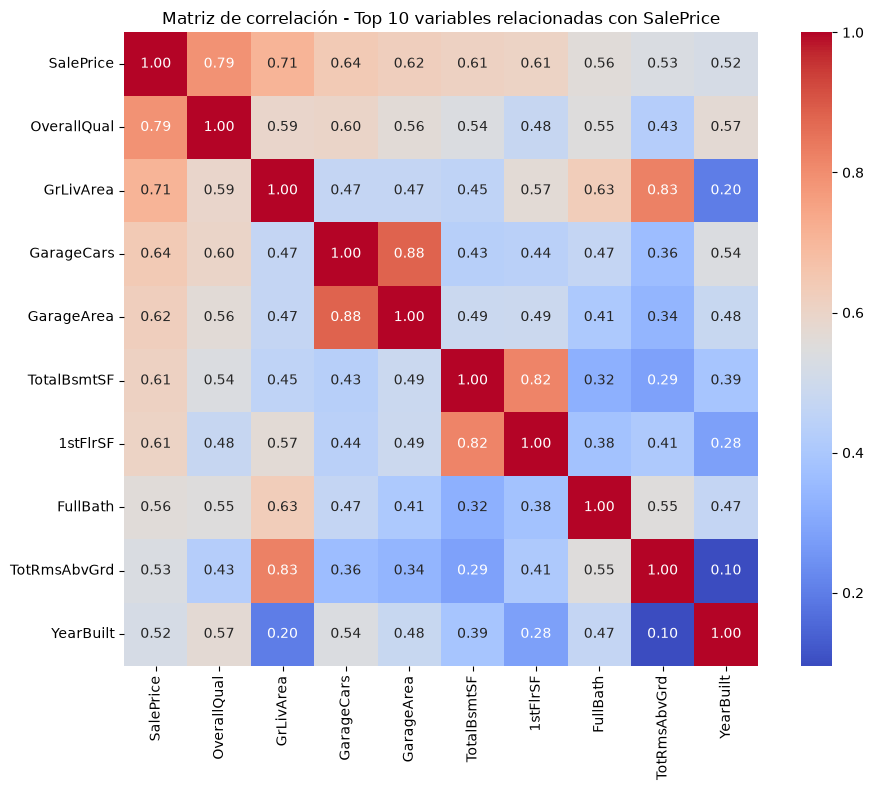

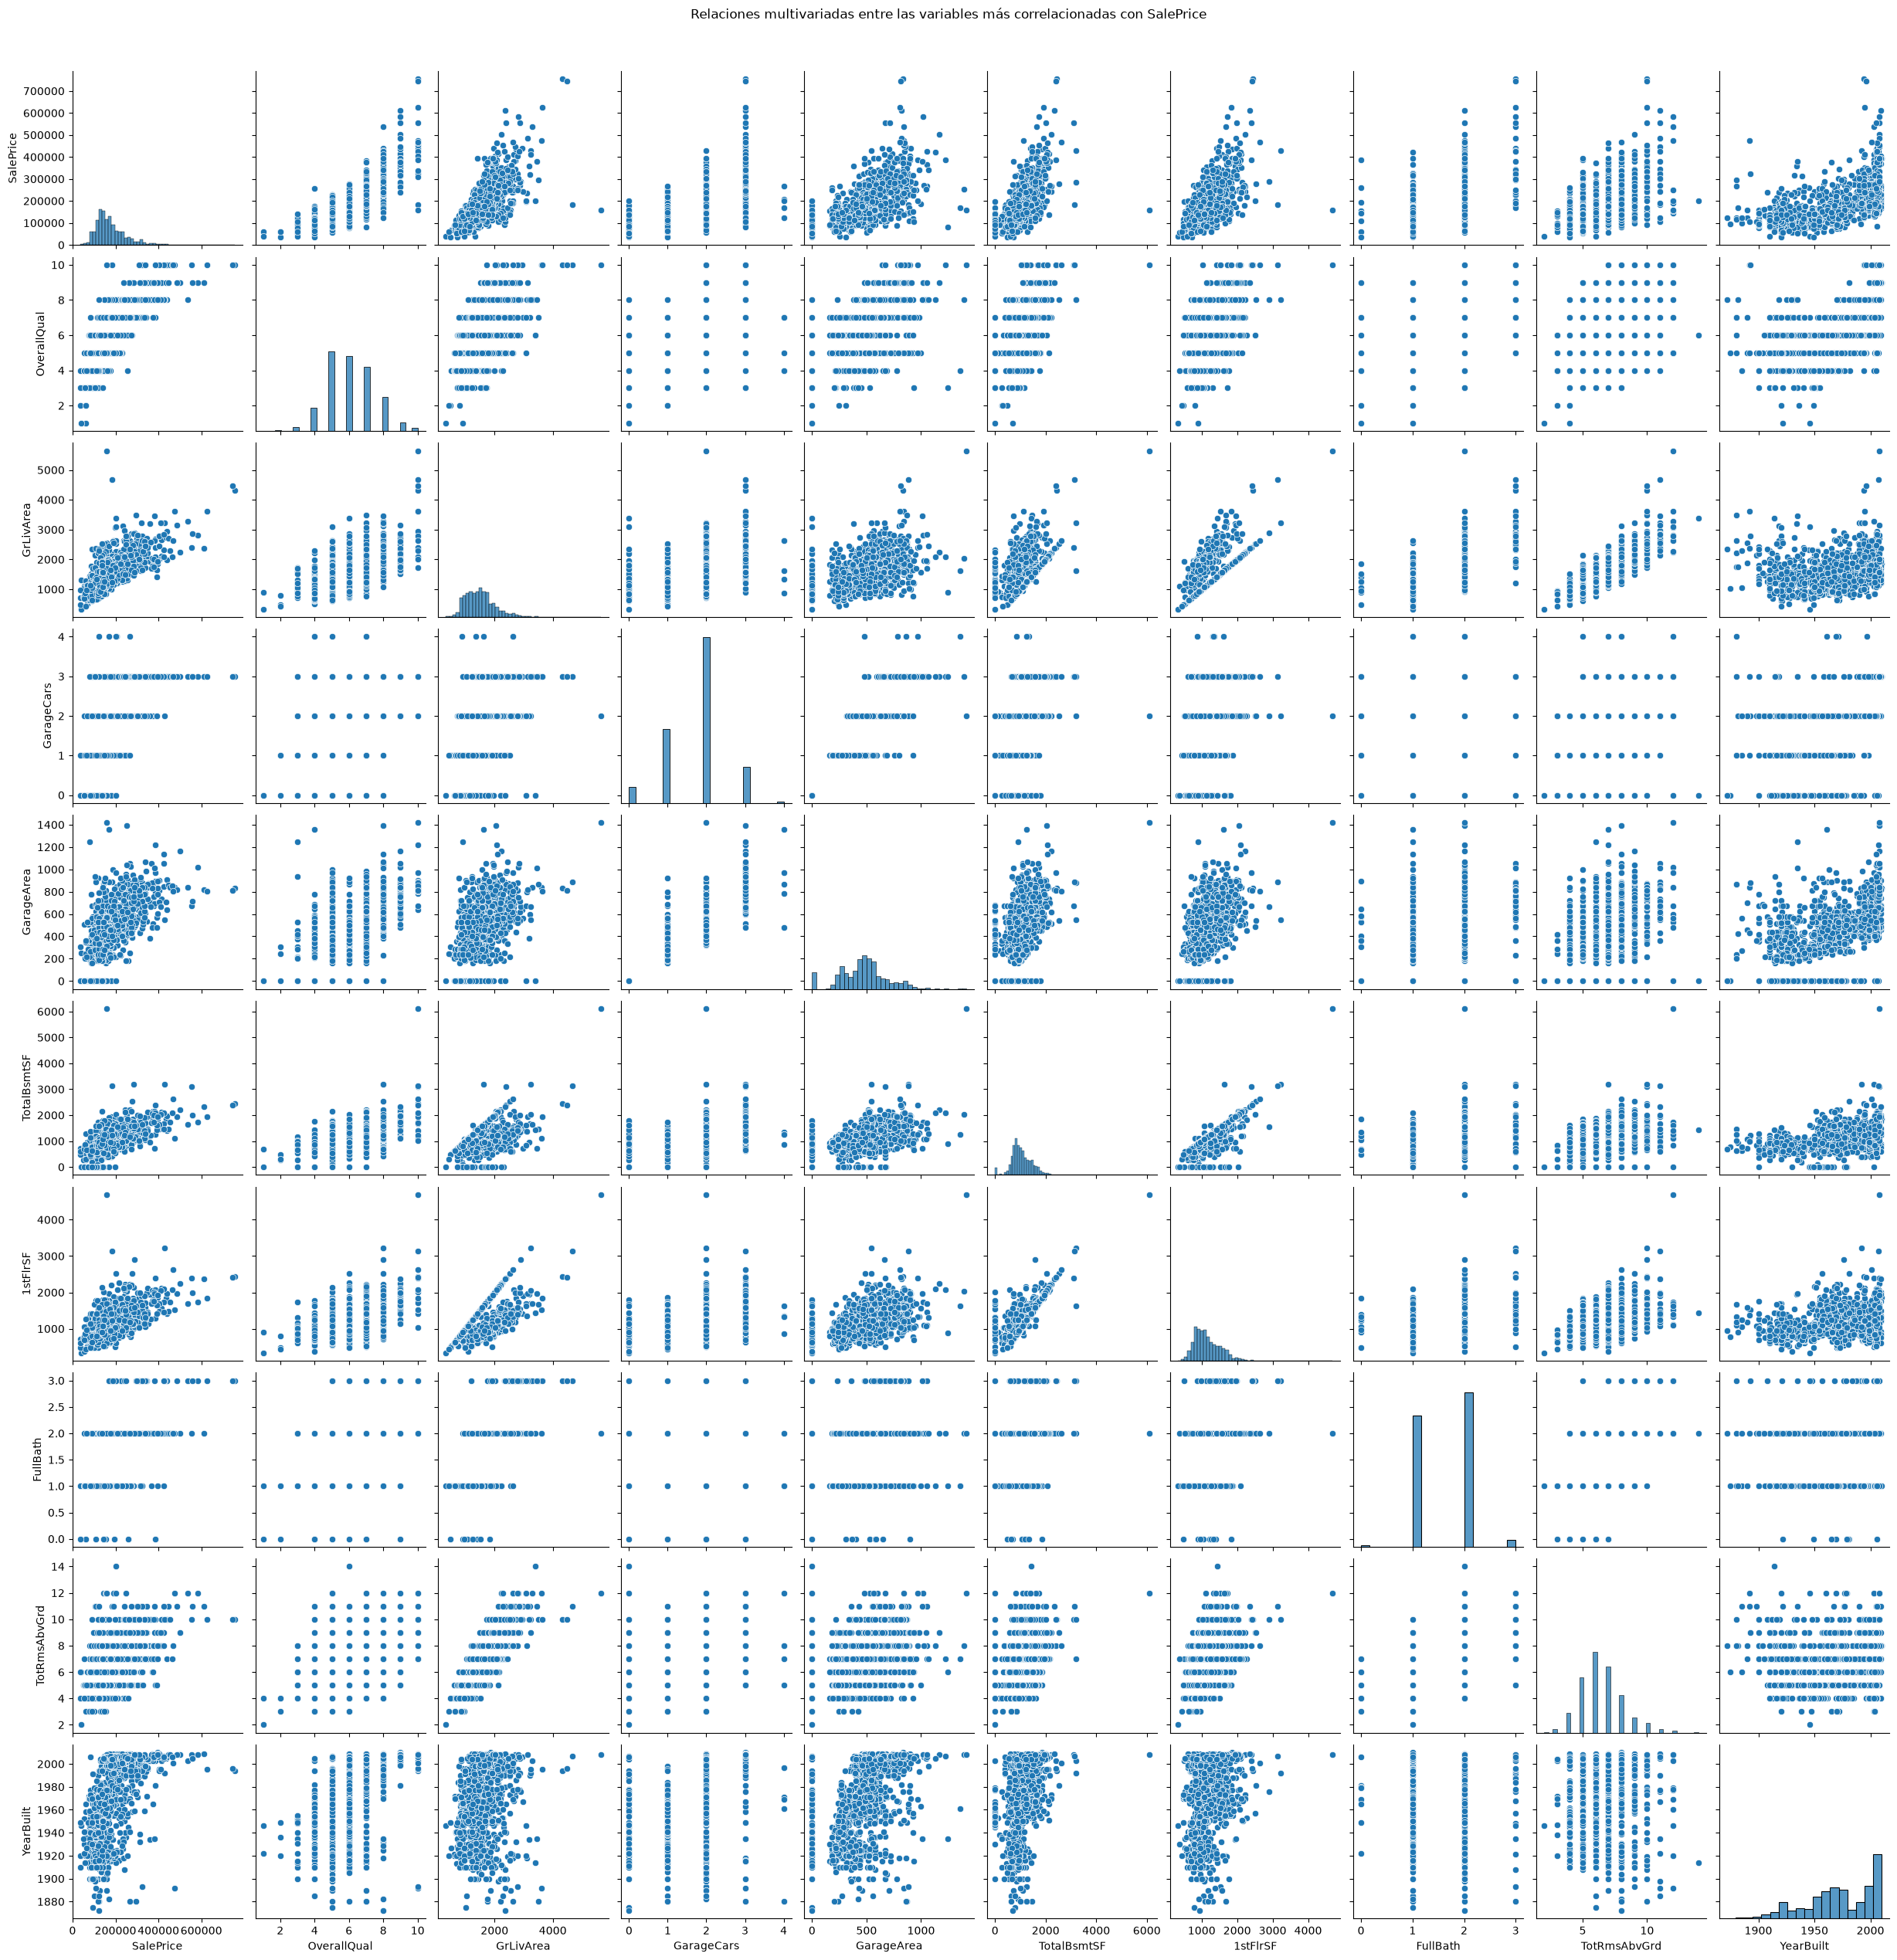

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionamos solo las columnas numéricas
df_numerico = df.select_dtypes(include=[np.number])

# Matriz de correlación
corr = df_numerico.corr()

# Nos quedamos con las variables más correlacionadas con SalePrice
top_corr_vars = corr['SalePrice'].abs().sort_values(ascending=False).head(10).index
corr_top = corr.loc[top_corr_vars, top_corr_vars]

# Heatmap de correlación entre las variables más relevantes
plt.figure(figsize=(10, 8))
sns.heatmap(corr_top, annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Matriz de correlación - Top 10 variables relacionadas con SalePrice')
plt.tight_layout()
plt.show()

# Pairplot para visualizar relaciones bivariadas entre esas variables
sns.pairplot(df[top_corr_vars])
plt.suptitle('Relaciones multivariadas entre las variables más correlacionadas con SalePrice', y=1.02)
plt.show()
